<a href="https://colab.research.google.com/github/Aigulya0/ml-practice/blob/main/Practice_05_Text_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import urllib.request
import zipfile
import os

# 1. Скачиваем датасет
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
urllib.request.urlretrieve(url, "/content/sms_spam.zip")

# 2. Распаковываем архив
with zipfile.ZipFile("/content/sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("/content/sms_data")

# 3. Находим нужный файл
source = "/content/sms_data/SMSSpamCollection"
destination = "/content/sms_spam.tsv"

# 4. Создаём файл TSV
import shutil
shutil.copy(source, destination)

# 5. Загружаем данные
df = pd.read_csv(
    destination,
    sep="\t",
    header=None,
    names=["label", "text"]
)

print("Датасет успешно загружен!")
print("Размер:", df.shape)
display(df.head())


Датасет успешно загружен!
Размер: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:

!pip -q install pandas numpy matplotlib seaborn scikit-learn nltk


In [3]:

import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nltk.download("stopwords")

print("Все библиотеки успешно импортированы!")


Все библиотеки успешно импортированы!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [4]:

df = pd.read_csv(
    "/content/sms_spam.tsv",
    sep="\t",
    header=None,
    names=["label", "text"],
    encoding="utf-8"
)

print("Размер датасета:", df.shape)
display(df.head())


Размер датасета: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:

print("Информация о датасете:")
df.info()

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nРаспределение классов:")
print(df["label"].value_counts())

print("\nДубликаты:", df.duplicated().sum())


Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Пропущенные значения:
label    0
text     0
dtype: int64

Распределение классов:
label
ham     4825
spam     747
Name: count, dtype: int64

Дубликаты: 403


In [6]:

df = df.dropna(subset=["label", "text"])
df = df.drop_duplicates().reset_index(drop=True)

print("Размер после очистки:", df.shape)


Размер после очистки: (5169, 2)


In [7]:

stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = str(text).lower()

    # Удаляем цифры
    text = re.sub(r"\d+", " ", text)

    # Удаляем пунктуацию
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Токенизация
    tokens = text.split()

    # Удаляем стоп-слова
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)

display(df[["text", "clean_text"]].head())


,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though


In [8]:

stemmer = PorterStemmer()

def tokenize_and_stem(text):
    tokens = text.split()
    return [stemmer.stem(word) for word in tokens]

df["tokens"] = df["clean_text"].apply(tokenize_and_stem)

df["processed_text"] = df["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

display(
    df[["text", "clean_text", "processed_text"]].head()
)


,text,clean_text,processed_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...,go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though,nah dont think goe usf live around though


In [9]:

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающие данные:", len(X_train))
print("Тестовые данные:", len(X_test))


Обучающие данные: 4135
Тестовые данные: 1034


In [10]:

def preprocess_text(text):
    cleaned = clean_text(text)
    tokens = tokenize_and_stem(cleaned)
    return " ".join(tokens)

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            preprocessor=preprocess_text,
            tokenizer=str.split,
            token_pattern=None,
            lowercase=False,
            min_df=2,
            max_df=0.95,
            max_features=5000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")


Модель успешно обучена!


In [11]:

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9749

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       903
        spam       0.89      0.92      0.90       131

    accuracy                           0.97      1034
   macro avg       0.94      0.95      0.94      1034
weighted avg       0.98      0.97      0.98      1034



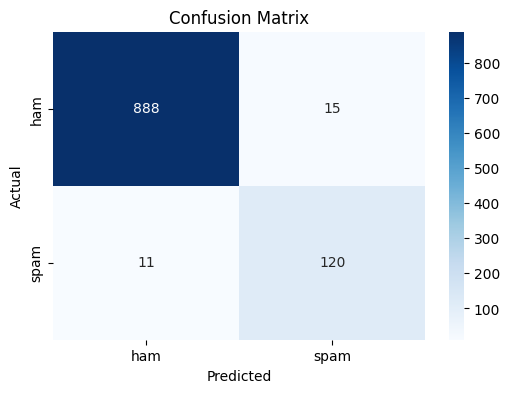

In [12]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [13]:

results = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

errors = results[
    results["actual"] != results["predicted"]
].copy()

print("Всего ошибок:", len(errors))

display(errors.head(5))


Всего ошибок: 26


,text,actual,predicted
63,I called and said all to him:)then he have to ...,ham,spam
247,I am waiting machan. Call me once you free.,ham,spam
293,Are you free now?can i call now?,ham,spam
305,"Sir, i am waiting for your call, once free ple...",ham,spam
308,Hi its LUCY Hubby at meetins all day Fri & I w...,spam,ham


In [14]:

def error_hypothesis(row):
    text = row["text"].lower()

    if len(text.split()) < 6:
        return "Короткое сообщение: недостаточно контекста"
    elif any(char.isdigit() for char in text):
        return "Цифры удалены, могла потеряться важная информация"
    elif row["actual"] == "spam":
        return "Спам может содержать слова, похожие на обычную переписку"
    else:
        return "Обычное сообщение может содержать слова, характерные для спама"

error_analysis = errors.head(5).copy()

error_analysis["hypothesis"] = error_analysis.apply(
    error_hypothesis,
    axis=1
)

display(error_analysis)


,text,actual,predicted,hypothesis
63,I called and said all to him:)then he have to ...,ham,spam,"Обычное сообщение может содержать слова, харак..."
247,I am waiting machan. Call me once you free.,ham,spam,"Обычное сообщение может содержать слова, харак..."
293,Are you free now?can i call now?,ham,spam,"Обычное сообщение может содержать слова, харак..."
305,"Sir, i am waiting for your call, once free ple...",ham,spam,"Обычное сообщение может содержать слова, харак..."
308,Hi its LUCY Hubby at meetins all day Fri & I w...,spam,ham,"Цифры удалены, могла потеряться важная информация"


In [15]:

new_messages = [
    "Congratulations! You won a free prize!",
    "Hi, are we meeting tomorrow?",
    "Claim your reward now!"
]

predictions = model.predict(new_messages)

for message, prediction in zip(
    new_messages, predictions
):
    print(message, "->", prediction)


Congratulations! You won a free prize! -> spam
Hi, are we meeting tomorrow? -> ham
Claim your reward now! -> spam


In [16]:

from google.colab import files

# Сохраняем обработанные данные
df.to_csv(
    "sms_spam_processed.csv",
    index=False
)

# Сохраняем анализ ошибок
error_analysis.to_csv(
    "error_analysis.csv",
    index=False
)

files.download("sms_spam_processed.csv")
files.download("error_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Практическая работа №6— Классификация текста с TF-IDF

## Вариант B — Предобработка и классификация текста

### Цель работы

Разработать пайплайн обработки текстовых данных, включающий очистку, нормализацию, токенизацию, TF-IDF векторизацию и обучение модели классификации.

### Используемый датасет

**Название:** SMS Spam Collection

**Источник:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)

Датасет содержит 5574 SMS-сообщения, разделённых на два класса:

- `ham` — обычные сообщения;
- `spam` — нежелательные рекламные сообщения.

### Используемые технологии

- Python
- Google Colab
- Pandas и NumPy
- NLTK
- Scikit-learn
- Matplotlib и Seaborn

### Этапы выполнения

**1. Загрузка и исследование данных**

Загружен датасет SMS Spam Collection. Проверены структура, пропущенные значения, распределение классов и дубликаты.

**2. Очистка текста**

Реализована собственная функция, которая:

- переводит текст в нижний регистр;
- удаляет цифры;
- удаляет знаки пунктуации;
- удаляет стоп-слова.

**3. Токенизация и стемминг**

Текст разбит на отдельные токены. Для нормализации слов использован алгоритм PorterStemmer из библиотеки NLTK.

**4. TF-IDF векторизация**

Использован TfidfVectorizer со следующими параметрами:

- `min_df=2`
- `max_df=0.95`
- `max_features=5000`

**5. Обучение классификатора**

Создан Pipeline, объединяющий предобработку, TF-IDF и Logistic Regression.

Данные разделены на обучающую (80%) и тестовую (20%) выборки.

**6. Оценка качества**

Для оценки использованы:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

**7. Анализ ошибок**

Выделены до пяти неправильно классифицированных сообщений. Для каждой ошибки сформулирована гипотеза о возможной причине.

### Структура проекта

```text
practice-05-text-classification/
├── data/
│   ├── sms_spam.tsv
│   └── sms_spam_processed.csv
├── notebooks/
│   └── Practice_05_Text_Classification.ipynb
├── results/
│   └── error_analysis.csv
└── README.md
```

### Результаты

Модель обучена для определения спама в SMS-сообщениях.

После запуска ноутбука необходимо указать полученные результаты:

- Accuracy: [вставить результат]
- Precision для spam: [вставить результат]
- Recall для spam: [вставить результат]
- F1-score для spam: [вставить результат]

### Вывод

В ходе практической работы реализован полный пайплайн классификации текста: от очистки и нормализации до векторизации и обучения модели.

TF-IDF позволяет представить текст в числовом виде, а Logistic Regression используется для определения класса сообщения.

Анализ ошибок помогает выявить ограничения модели и определить возможные направления улучшения.

### Автор

Практическая работа №5

**Среда разработки:** Google Colab

**Язык программирования:** Python